# Google MLCC: standalone Colab edition

Run the setup cell in a fresh Colab runtime, then run every cell from top to bottom. Setup downloads the original course data and installs compatible dependencies, including `google-ml-edu` (imported as `ml_edu`) for taxi/rice. No course ZIP is required. TensorFlow 2.21 and Keras 3.12+ adapt those exercises to current Python 3.13 Colab; the original TF 2.18/NumPy 2.0 pins do not support Python 3.13.

`USE_GOOGLE_DRIVE=True` saves measured results, models, and task execution evidence to `MyDrive/HaiLong_Colab_Results/01_google_mlcc`. Save this notebook in Drive and save it after running to retain cell outputs. The completion report requires every computational stage and full original data/epochs. Website quizzes and interactive exercises have separate progress.

Original source: https://raw.githubusercontent.com/google/eng-edu/main/ml/cc/exercises/binary_classification_rice.ipynb


In [1]:
# Standalone Google MLCC setup. Start a fresh Colab runtime, then Run all.
# No ZIP or eng-edu clone is required. Full original data/tasks only.
from pathlib import Path
import os, sys, subprocess, importlib.metadata as metadata
import hashlib, json, shutil, urllib.request, platform, uuid
from datetime import datetime, timezone
from packaging.requirements import Requirement

USE_GOOGLE_DRIVE = True  #@param {type:"boolean"}
QUICK_RUN = False  # retained for compatibility; full completion requires False
if QUICK_RUN:
    raise ValueError('Use QUICK_RUN=False to execute the full original exercise.')
NOTEBOOK_NAME = '02_binary_classification_rice.ipynb'
DEPENDENCY_PROFILE = 'google'
REQUIREMENTS = ['google-ml-edu==0.1.3', 'tensorflow==2.21.0', 'keras>=3.12,<4', 'numpy>=2,<3', 'pandas>=2.2,<3', 'matplotlib>=3.9,<4', 'plotly>=5,<7', 'scikit-learn>=1.5,<2']
REQUIRED_TASKS = ['task_1_describe_data', 'task_2_visualize_3d', 'training_only_normalization_and_split', 'baseline_training_60_epochs', 'baseline_validation', 'all_features_training_60_epochs', 'all_features_validation', 'model_comparison', 'heldout_test']
DATA_SOURCES = [{'filename': 'Rice_Cammeo_Osmancik.csv', 'url': 'https://download.mlcc.google.com/mledu-datasets/Rice_Cammeo_Osmancik.csv', 'sha256': '15234fbc17f2b57a05e81d1088a18c0f0aded87c4397c72437eda03f54acdc2c', 'rows': 3810}]
ORIGINAL_SOURCE = 'https://raw.githubusercontent.com/google/eng-edu/main/ml/cc/exercises/binary_classification_rice.ipynb'
VISUALIZATION_ADAPTATION = None

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# TensorFlow 2.21 has Python 3.13 wheels; original TF 2.18 pins do not.
# Set Keras mode before importing TensorFlow or Keras.
if DEPENDENCY_PROFILE in ('google', 'fairness'):
    if DEPENDENCY_PROFILE == 'fairness':
        if any(n in sys.modules for n in ('tensorflow', 'keras', 'tf_keras')):
            if os.environ.get('TF_USE_LEGACY_KERAS') != '1':
                raise RuntimeError('Select Runtime > Disconnect and delete runtime, reconnect, then Run all: MinDiff needs legacy Keras selected before TensorFlow import.')
        os.environ['TF_USE_LEGACY_KERAS'] = '1'
    else:
        if os.environ.get('TF_USE_LEGACY_KERAS') == '1' and any(n in sys.modules for n in ('tensorflow', 'keras', 'tf_keras')):
            raise RuntimeError('Start a fresh runtime after fairness before running this Keras 3 notebook.')
        os.environ.pop('TF_USE_LEGACY_KERAS', None)
    os.environ['KERAS_BACKEND'] = 'tensorflow'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['COURSE_SMOKE'] = '0'
os.environ['WANDB_MODE'] = 'offline'

# google-ml-edu is the distribution that provides the ml_edu import.
IMPORT_NAMES = {'google-ml-edu':'ml_edu', 'tf-keras':'tf_keras',
    'tensorflow-model-remediation':'tensorflow_model_remediation',
    'scikit-learn':'sklearn'}
def installed_version(package):
    try:
        return metadata.version(package)
    except metadata.PackageNotFoundError:
        return None
missing, loaded_changes = [], []
for text in REQUIREMENTS:
    req = Requirement(text)
    version = installed_version(req.name)
    if version is None or version not in req.specifier:
        missing.append(text)
        module = IMPORT_NAMES.get(req.name, req.name.replace('-', '_'))
        if module in sys.modules:
            loaded_changes.append(module)
if missing and IN_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--disable-pip-version-check', *missing])
    if loaded_changes:
        raise RuntimeError('Installed required versions. Select Runtime > Restart session, then Run all again; old loaded modules: ' + ', '.join(loaded_changes))
elif missing:
    raise RuntimeError('Prepared for Colab. Missing compatible local packages: ' + ', '.join(missing))

if IN_COLAB:
    COURSE_ROOT = Path('/content/HaiLong_Colab_Exercises')
else:
    COURSE_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                        if (p / 'colab_runtime.py').is_file()), None)
    if COURSE_ROOT is None:
        raise RuntimeError('Run in Colab or inside HaiLong_Colab_Exercises.')
COURSE_DIR = COURSE_ROOT / '01_google_mlcc'
COURSE_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(COURSE_DIR)
DATA = COURSE_DIR / 'data'
DATA.mkdir(exist_ok=True)
DRIVE_DIR = None
if IN_COLAB and USE_GOOGLE_DRIVE:
    if not Path('/content/drive/MyDrive').is_dir():
        drive.mount('/content/drive', timeout_ms=300000)
    DRIVE_DIR = Path('/content/drive/MyDrive/HaiLong_Colab_Results/01_google_mlcc')
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)
for folder in ('results', 'models'):
    target = COURSE_DIR / folder
    if DRIVE_DIR is not None:
        (DRIVE_DIR / folder).mkdir(exist_ok=True)
        if not target.exists():
            target.symlink_to(DRIVE_DIR / folder, target_is_directory=True)
    target.mkdir(exist_ok=True)
RESULTS, MODELS = COURSE_DIR / 'results', COURSE_DIR / 'models'
for spec in DATA_SOURCES:
    target = DATA / spec['filename']
    if not target.is_file():
        temporary = target.with_suffix(target.suffix + '.download')
        print('Downloading original Google course data:', spec['url'])
        urllib.request.urlretrieve(spec['url'], temporary)
        if hashlib.sha256(temporary.read_bytes()).hexdigest() != spec['sha256']:
            raise ValueError('Downloaded dataset differs from verified original: ' + spec['filename'])
        temporary.replace(target)
    if hashlib.sha256(target.read_bytes()).hexdigest() != spec['sha256']:
        raise ValueError('Existing data differs from the original course dataset: ' + str(target))

EXECUTED_TASKS = {}
COLAB_CONTEXT = {'notebook': NOTEBOOK_NAME, 'run_id': str(uuid.uuid4()),
    'started_at_utc': datetime.now(timezone.utc).isoformat(),
    'in_hosted_colab': IN_COLAB, 'quick_run': False,
    'python': platform.python_version(),
    'versions': {Requirement(r).name: installed_version(Requirement(r).name) for r in REQUIREMENTS},
    'original_source': ORIGINAL_SOURCE, 'data_sources': DATA_SOURCES,
    'visualization_adaptation': VISUALIZATION_ADAPTATION}
def mark_task(name, **evidence):
    if name not in REQUIRED_TASKS:
        raise KeyError(name)
    EXECUTED_TASKS[name] = {'recorded_at_utc': datetime.now(timezone.utc).isoformat(), **evidence}
    checkpoint = {**COLAB_CONTEXT, 'last_completed_stage': name,
        'updated_at_utc': datetime.now(timezone.utc).isoformat(),
        'missing_tasks': sorted(set(REQUIRED_TASKS) - set(EXECUTED_TASKS)),
        'task_evidence': EXECUTED_TASKS, 'course_website_completion_confirmed': False}
    (RESULTS / (Path(NOTEBOOK_NAME).stem + '_progress.json')).write_text(
        json.dumps(checkpoint, indent=2, allow_nan=False), encoding='utf-8')
    if DRIVE_DIR is not None:
        for folder in ('results', 'models'):
            source, target = COURSE_DIR / folder, DRIVE_DIR / folder
            if source.resolve() != target.resolve():
                shutil.copytree(source, target, dirs_exist_ok=True)
def finish_run(context):
    missing_tasks = sorted(set(REQUIRED_TASKS) - set(EXECUTED_TASKS))
    if missing_tasks:
        raise RuntimeError('Required exercise stages did not run: ' + ', '.join(missing_tasks))
    report = {**context, 'finished_at_utc': datetime.now(timezone.utc).isoformat(),
        'full_original_computational_tasks_executed': True,
        'course_website_completion_confirmed': False,
        'required_tasks': REQUIRED_TASKS, 'task_evidence': EXECUTED_TASKS,
        'note': 'Execution evidence covers this notebook. It does not certify website quizzes, interactive exercises, or personal reflection.'}
    path = RESULTS / (Path(NOTEBOOK_NAME).stem + '_completion.json')
    path.write_text(json.dumps(report, indent=2, allow_nan=False), encoding='utf-8')
    if DRIVE_DIR is not None:
        for folder in ('results', 'models'):
            source, target = COURSE_DIR / folder, DRIVE_DIR / folder
            if source.resolve() != target.resolve():
                shutil.copytree(source, target, dirs_exist_ok=True)
        print('Saved computational progress and artifacts to:', DRIVE_DIR)
    print('Full original computational stages executed:', NOTEBOOK_NAME)
    print('Completion evidence:', path)
    return report
print('Setup ready:', NOTEBOOK_NAME, '| full course data |', DEPENDENCY_PROFILE)

Setup ready: 02_binary_classification_rice.ipynb | full course data | google


# Completed Google MLCC: rice classification
Source: https://github.com/google/eng-edu/blob/main/ml/cc/exercises/binary_classification_rice.ipynb
Apache-2.0 Google notebook. Completed 3-D plot and seven-feature model; added ROC/threshold experiments and validation-based selection. Normalisation is fitted on training rows only, as required by LO4.


In [2]:
#@title Copyright 2023 Google LLC. Double-click for license information.
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

# Colabs

Machine Learning Crash Course uses Colaboratories (Colabs) for all programming exercises. Colab is Google's implementation of [Jupyter Notebook](https://jupyter.org/). For more information about Colabs and how to use them, go to [Welcome to Colaboratory](https://research.google.com/colaboratory).

# Binary classification

In this Colab, you'll complete the following tasks:
- Examine a dataset containing measurements derived from images of two species of Turkish rice.
- Create a binary classifier to sort grains of rice into the two species.
- Evaluate the performance of the model.

## Learning objectives

By completing this Colab, you'll learn:
- How to train a binary classifier.
- How to calculate metrics for a binary classifier at different thresholds.
- How to compare AUC and ROC of two different models.

## Dataset

This Colab uses the Cinar and Koklu 2019 Osmancik and Cammeo rice dataset.

Provided with a CC0 license (see [Kaggle](https://www.kaggle.com/datasets/muratkokludataset/rice-dataset-commeo-and-osmancik) for more documentation; lengths and area are given in pixels). Cinar and Koklu also provide datasets for multiclass (5 species of rice), pistachios, raisins, grape leaves, and so on, at their [repository](https://www.muratkoklu.com/datasets/).

### Citation

Cinar, I. and Koklu, M., (2019). “Classification of Rice Varieties Using Artificial Intelligence Methods.” *International Journal of Intelligent Systems and Applications in Engineering*, 7(3), 188-194.

DOI: https://doi.org/10.18201/ijisae.2019355381


# Load Imports

In [3]:
from pathlib import Path
import os
os.environ.setdefault('KERAS_BACKEND', 'tensorflow')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '1')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
# Colab setup above selects this course folder.
DATA = Path('data')
RESULTS = Path('results'); RESULTS.mkdir(exist_ok=True)

In [4]:
# @title Load the imports

import keras
import ml_edu.experiment
import ml_edu.results
import numpy as np
import pandas as pd
import plotly.express as px

# The following lines adjust the granularity of reporting.
pd.options.display.max_rows = 10
pd.options.display.float_format = "{:.1f}".format

print("Ran the import statements.")

Ran the import statements.


In [5]:
rice_dataset_raw = pd.read_csv(DATA / 'Rice_Cammeo_Osmancik.csv')

assert len(rice_dataset_raw) == 3810, 'Use the complete original rice dataset.'

Once the dataset has been loaded via the cell above, select specific columns to show summary statistics of the numerical features in the dataset.

See the Kaggle [dataset documentation](https://www.kaggle.com/datasets/muratkokludataset/rice-dataset-commeo-and-osmancik), especially the **Provenance** section, for explanations of what each feature means and how they were calculated.

In [6]:
# @title
# Read and provide statistics on the dataset.
rice_dataset = rice_dataset_raw[[
    'Area',
    'Perimeter',
    'Major_Axis_Length',
    'Minor_Axis_Length',
    'Eccentricity',
    'Convex_Area',
    'Extent',
    'Class',
]]

rice_dataset.describe()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
count,3810.0,3810.0,3810.0,3810.0,3810.0,3810.0,3810.0
mean,12667.7,454.2,188.8,86.3,0.9,12952.5,0.7
std,1732.4,35.6,17.4,5.7,0.0,1777.0,0.1
min,7551.0,359.1,145.3,59.5,0.8,7723.0,0.5
25%,11370.5,426.1,174.4,82.7,0.9,11626.2,0.6
50%,12421.5,448.9,185.8,86.4,0.9,12706.5,0.6
75%,13950.0,483.7,203.6,90.1,0.9,14284.0,0.7
max,18913.0,548.4,239.0,107.5,0.9,19099.0,0.9


## Task 1: Describe the data

From the summary statistics above, answer the following questions:
- What are the min and max lengths (major axis length, given in pixels) of the rice grains?
- What is the range of areas between the smallest and largest rice grains?
- How many standard deviations (`std`) is the largest rice grain's perimeter from the mean?

In [7]:
# @title Solutions (run the cell to get the answers)

print(
    f'The shortest grain is {rice_dataset.Major_Axis_Length.min():.1f}px long,'
    f' while the longest is {rice_dataset.Major_Axis_Length.max():.1f}px.'
)
print(
    f'The smallest rice grain has an area of {rice_dataset.Area.min()}px, while'
    f' the largest has an area of {rice_dataset.Area.max()}px.'
)
print(
    'The largest rice grain, with a perimeter of'
    f' {rice_dataset.Perimeter.max():.1f}px, is'
    f' ~{(rice_dataset.Perimeter.max() - rice_dataset.Perimeter.mean())/rice_dataset.Perimeter.std():.1f} standard'
    f' deviations ({rice_dataset.Perimeter.std():.1f}) from the mean'
    f' ({rice_dataset.Perimeter.mean():.1f}px).'
)
print(
    f'This is calculated as: ({rice_dataset.Perimeter.max():.1f} -'
    f' {rice_dataset.Perimeter.mean():.1f})/{rice_dataset.Perimeter.std():.1f} ='
    f' {(rice_dataset.Perimeter.max() - rice_dataset.Perimeter.mean())/rice_dataset.Perimeter.std():.1f}'
)

rice_dataset.describe().to_csv(RESULTS / 'rice_statistics.csv')
mark_task('task_1_describe_data', rows=len(rice_dataset))

The shortest grain is 145.3px long, while the longest is 239.0px.
The smallest rice grain has an area of 7551px, while the largest has an area of 18913px.
The largest rice grain, with a perimeter of 548.4px, is ~2.6 standard deviations (35.6) from the mean (454.2px).
This is calculated as: (548.4 - 454.2)/35.6 = 2.6


# Explore the dataset

Plot some of the features against each other, including in 3D.


In [8]:
# Create five 2D plots of the features against each other, color-coded by class.
for x_axis_data, y_axis_data in [
    ('Area', 'Eccentricity'),
    ('Convex_Area', 'Perimeter'),
    ('Major_Axis_Length', 'Minor_Axis_Length'),
    ('Perimeter', 'Extent'),
    ('Eccentricity', 'Major_Axis_Length'),
]:
  px.scatter(rice_dataset, x=x_axis_data, y=y_axis_data, color='Class').show()

## Task 2: Visualize samples in 3D

Try graphing three of the features in 3D against each other.

In [9]:
px.scatter_3d(rice_dataset, x='Eccentricity', y='Area', z='Major_Axis_Length', color='Class').show()

mark_task('task_2_visualize_3d', axes=['Eccentricity','Area','Major_Axis_Length'])

In [10]:
# @title One possible solution

# Plot major and minor axis length and eccentricity, with observations
# color-coded by class.
px.scatter_3d(
    rice_dataset,
    x='Eccentricity',
    y='Area',
    z='Major_Axis_Length',
    color='Class',
).show()

If we were to pick three features, it seems that major axis length, area, and eccentricity might contain most of the information that differentiates the two classes. Other combinations may work as well.

Run the previous code cell to graph those three features if you haven't already.

It seems like a distinct class boundary appears in the plane of these three features. We'll train a model on just these features, then another model on the complete set of features, and compare their performance.

## Normalize data

When creating a model with multiple features, the values of each feature should span roughly the same range.  If one feature's values range from 500 to 100,000 and another feature's values range from 2 to 12, the model will need to have weights of extremely low or extremely high values to be able to combine these features effectively. This could result in a low quality model.  To avoid this,
[normalize](https://developers.google.com/machine-learning/glossary/#normalization) features in a multi-feature model.

This can be done by converting each raw value to its Z-score. The **Z-score** for a given value is how many standard deviations away from the mean the value is.

Consider a feature with a mean of 60 and a standard deviation of 10.

The raw value 75 would have a Z-score of +1.5:

```
  Z-score = (75 - 60) / 10 = +1.5
```

The raw value 38 would have a Z-score of -2.2:

```
  Z-score = (38 - 60) / 10 = -2.2
```

Now normalize the numerical values in the rice dataset by converting them to Z-scores.

In [11]:
# Fix data leakage: compute normalisation parameters using only the rows
# that the later deterministic 80/10/10 split assigns to training.
numerical_features = rice_dataset.select_dtypes('number').columns
raw_shuffled = rice_dataset.sample(frac=1, random_state=100)
training_rows = raw_shuffled.iloc[:round(len(raw_shuffled)*.8)]
feature_mean = training_rows[numerical_features].mean()
feature_std = training_rows[numerical_features].std().replace(0, 1)
normalized_dataset = (rice_dataset[numerical_features]-feature_mean)/feature_std
normalized_dataset['Class'] = rice_dataset['Class']
print('Normalisation fitted on',len(training_rows),'training rows only.')

Normalisation fitted on 3048 training rows only.


# Set the random seeds

To make experiments reproducible, we set the seed of the random number generators. This means that the order in which the data is shuffled, the values of the random weight initializations, etc, will all be the same each time the colab is run.

In [12]:
keras.utils.set_random_seed(42)

## Label and split data

To train the model, we'll arbritrarily assign the Cammeo species a label of '1' and the Osmancik species a label of '0'.

In [13]:
# Create a column setting the Cammeo label to '1' and the Osmancik label to '0'
# then show 10 randomly selected rows.
normalized_dataset['Class_Bool'] = (
    # Returns true if class is Cammeo, and false if class is Osmancik
    normalized_dataset['Class'] == 'Cammeo'
).astype(int)
normalized_dataset.sample(10)

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class,Class_Bool
1011,-0.1,0.1,-0.1,0.1,-0.1,-0.0,-1.0,Cammeo,1
3185,-0.2,-0.5,-0.5,0.4,-0.8,-0.2,-0.3,Osmancik,0
3698,0.1,-0.2,-0.4,0.9,-1.1,0.1,-0.2,Osmancik,0
897,0.2,0.5,0.8,-0.5,1.2,0.2,1.5,Cammeo,1
3245,-1.3,-1.3,-0.9,-1.7,0.4,-1.4,-1.1,Osmancik,0
478,0.2,0.2,0.4,-0.0,0.5,0.2,1.7,Cammeo,1
1731,-0.4,-0.8,-0.8,0.3,-1.1,-0.5,-0.4,Osmancik,0
1025,0.5,0.7,0.6,0.3,0.5,0.6,-0.5,Cammeo,1
429,1.2,1.2,1.4,0.6,1.0,1.1,1.8,Cammeo,1
1330,-0.4,-0.1,0.4,-1.3,1.4,-0.5,-0.1,Cammeo,1


We can then randomize and partition the dataset into train, validation, and test splits, consisting of 80%, 10%, and 10% of the dataset respectively.

We will use the training data to learn the model parameters, then use the validation data to evaluate different models, and finally use the test data to compute the final metrics for the model that performed best on the validation data.

In [14]:
# Create indices at the 80th and 90th percentiles
number_samples = len(normalized_dataset)
index_80th = round(number_samples * 0.8)
index_90th = index_80th + round(number_samples * 0.1)

# Randomize order and split into train, validation, and test with a .8, .1, .1 split
shuffled_dataset = normalized_dataset.sample(frac=1, random_state=100)
train_data = shuffled_dataset.iloc[0:index_80th]
validation_data = shuffled_dataset.iloc[index_80th:index_90th]
test_data = shuffled_dataset.iloc[index_90th:]

# Show the first five rows of the last split
test_data.head()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class,Class_Bool
2405,-0.4,-0.7,-0.8,0.3,-1.2,-0.5,0.3,Osmancik,0
3062,-0.2,-0.0,0.2,-0.7,0.8,-0.2,1.6,Osmancik,0
1155,1.4,1.2,1.1,1.2,0.3,1.3,0.7,Cammeo,1
660,1.2,1.0,0.8,1.3,-0.0,1.2,-0.6,Cammeo,1
2451,-1.2,-1.2,-1.4,-0.3,-1.5,-1.1,0.1,Osmancik,0


It's important to prevent the model from getting the label as input during training, which is called label leakage. This can be done by storing features and labels as separate variables.

In [15]:
label_columns = ['Class', 'Class_Bool']

train_features = train_data.drop(columns=label_columns)
train_labels = train_data['Class_Bool'].to_numpy()
validation_features = validation_data.drop(columns=label_columns)
validation_labels = validation_data['Class_Bool'].to_numpy()
test_features = test_data.drop(columns=label_columns)
test_labels = test_data['Class_Bool'].to_numpy()

assert len(train_data) == 3048 and len(validation_data) == 381 and len(test_data) == 381
assert set(train_data.index) == set(training_rows.index)
assert set(train_data.index).isdisjoint(validation_data.index)
assert set(train_data.index).isdisjoint(test_data.index)
assert set(validation_data.index).isdisjoint(test_data.index)
mark_task('training_only_normalization_and_split', train_rows=3048, validation_rows=381, test_rows=381)

## Train the model

### Choose the input features

To start with, we'll train a model on `Eccentricity`, `Major_Axis_Length,` and `Area`.

In [16]:
# Name of the features we'll train our model on.
input_features = [
    'Eccentricity',
    'Major_Axis_Length',
    'Area',
]

## Define functions that build and train a model

The following code cell defines two functions:

  * `create_model(inputs, learning_rate, metrics)`, which defines the model's architecture.
  * `train_model(model, dataset, epochs, label_name, batch_size, shuffle)`, uses input features and labels to train the model.

Note: create_model applies the sigmoid function to perform [logistic regression](https://developers.google.com/machine-learning/crash-course/logistic-regression).

We also define two helpful data structures: `ExperimentSettings` and `Experiment`. We use these simple classes to keep track of our experiments, allowing us to know what hyperparameters were used and what the results were. In `ExperimentSettings`, we store all values describing an experiment (i.e., hyperparameters). Then, we store the results of a training run (i.e., the model and the training metrics) into an `Experiment` instance, along with the `ExperimentSettings` used for that experiment.

In [17]:
# @title Define the functions that create and train a model.


def create_model(
    settings: ml_edu.experiment.ExperimentSettings,
    metrics: list[keras.metrics.Metric],
) -> keras.Model:
  """Create and compile a simple classification model."""
  model_inputs = {
      feature: keras.Input(name=feature, shape=(1,))
      for feature in settings.input_features
  }
  # Use a Concatenate layer to assemble the different inputs into a single
  # tensor which will be given as input to the Dense layer.
  # For example: [input_1[0][0], input_2[0][0]]

  concatenated_inputs = keras.layers.Concatenate()(list(model_inputs.values()))
  model_output = keras.layers.Dense(
      units=1, name='dense_layer', activation=keras.activations.sigmoid
  )(concatenated_inputs)
  model = keras.Model(inputs=model_inputs, outputs=model_output)
  # Call the compile method to transform the layers into a model that
  # Keras can execute.  Notice that we're using a different loss
  # function for classification than for regression.
  model.compile(
      optimizer=keras.optimizers.RMSprop(
          settings.learning_rate
      ),
      loss=keras.losses.BinaryCrossentropy(),
      metrics=metrics,
  )
  return model


def train_model(
    experiment_name: str,
    model: keras.Model,
    dataset: pd.DataFrame,
    labels: np.ndarray,
    settings: ml_edu.experiment.ExperimentSettings,
) -> ml_edu.experiment.Experiment:
  """Feed a dataset into the model in order to train it."""

  # The x parameter of keras.Model.fit can be a list of arrays, where
  # each array contains the data for one feature.
  features = {
      feature_name: np.array(dataset[feature_name])
      for feature_name in settings.input_features
  }

  history = model.fit(
      x=features,
      y=labels,
      batch_size=settings.batch_size,
      epochs=settings.number_epochs, verbose=0,
  )

  return ml_edu.experiment.Experiment(
      name=experiment_name,
      settings=settings,
      model=model,
      epochs=history.epoch,
      metrics_history=pd.DataFrame(history.history),
  )


print('Defined the create_model and train_model functions.')

Defined the create_model and train_model functions.


## Define a plotting function

The following [matplotlib](https://developers.google.com/machine-learning/glossary/#matplotlib) function plots one or more curves, showing how various classification metrics change with each epoch.

## Invoke the creating, training, and plotting functions

The following code specifies the hyperparameters, invokes the
functions to create and train the model, then plots the results, including accuracy, precision, and recall.

Classification threshold is set at .35. Try playing with the threshold, then the learning rate, to see what changes.

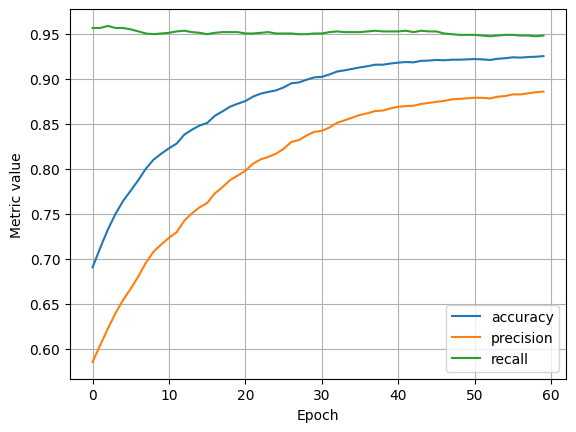

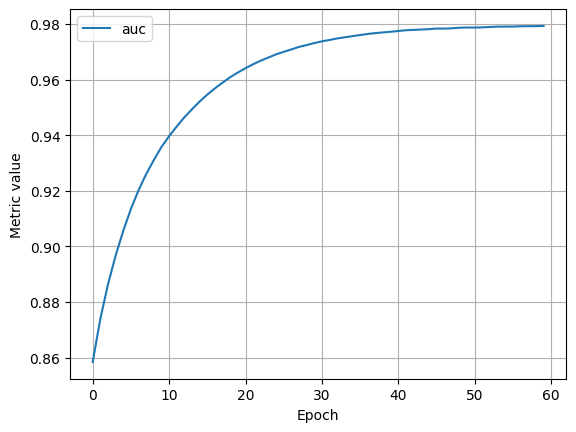

In [18]:
# Let's define our first experiment settings.
settings = ml_edu.experiment.ExperimentSettings(
    learning_rate=0.001,
    number_epochs=60,
    batch_size=100,
    classification_threshold=0.35,
    input_features=input_features,
)

metrics = [
    keras.metrics.BinaryAccuracy(
        name='accuracy', threshold=settings.classification_threshold
    ),
    keras.metrics.Precision(
        name='precision', thresholds=settings.classification_threshold
    ),
    keras.metrics.Recall(
        name='recall', thresholds=settings.classification_threshold
    ),
    keras.metrics.AUC(num_thresholds=100, name='auc'),
]

# Establish the model's topography.
model = create_model(settings, metrics)

# Train the model on the training set.
experiment = train_model(
    'baseline', model, train_features, train_labels, settings
)

# Plot metrics vs. epochs
ml_edu.results.plot_experiment_metrics(experiment, ['accuracy', 'precision', 'recall'])
ml_edu.results.plot_experiment_metrics(experiment, ['auc'])

assert len(experiment.epochs) == 60
experiment.metrics_history.to_csv(RESULTS / 'rice_baseline_history.csv', index=False)
experiment.model.save(MODELS / 'rice_baseline.keras')
mark_task('baseline_training_60_epochs', epochs=60, features=list(settings.input_features), classification_threshold=float(settings.classification_threshold))

AUC is calculated across all possible thresholds (in practice in the code above, 100 thresholds), while accuracy, precision, and recall are calculated for only the specified threshold. For this reason they are shown separately above.

## Evaluate the model against the validation set

At the end of model training, you ended up with a certain accuracy against the *training set*. Invoke the following code cell to determine your model's accuracy against the *validation set*.

In [19]:
def compare_train_validation(experiment: ml_edu.experiment.Experiment, validation_metrics: dict[str, float]):
  print('Comparing metrics between train and validation:')
  for metric, validation_value in validation_metrics.items():
    print('------')
    print(f'Train {metric}: {experiment.get_final_metric_value(metric):.4f}')
    print(f'Validation {metric}:  {validation_value:.4f}')


# Evaluate validation metrics
validation_metrics = experiment.evaluate(validation_features, validation_labels)
compare_train_validation(experiment, validation_metrics)

pd.DataFrame([validation_metrics]).to_csv(RESULTS / 'rice_baseline_validation.csv', index=False)
mark_task('baseline_validation', metrics={k:float(v) for k,v in validation_metrics.items()})

Comparing metrics between train and validation:
------
Train accuracy: 0.9252
Validation accuracy:  0.8950
------
Train auc: 0.9793
Validation auc:  0.9722
------
Train loss: 0.1844
Validation loss:  0.2155
------
Train precision: 0.8858
Validation precision:  0.8449
------
Train recall: 0.9481
Validation recall:  0.9349


It appears that the model, which achieved ~92% accuracy on the training data, still shows an accuracy of about 90% on the validation data. Can we do better? Let's train a model using all seven available features and compare the AUC.

In [20]:
all_input_features = ['Eccentricity','Major_Axis_Length','Minor_Axis_Length','Area','Convex_Area','Perimeter','Extent']

In [21]:
#@title Solution
# Features used to train the model on.
# Specify all features.
all_input_features = [
  'Eccentricity',
  'Major_Axis_Length',
  'Minor_Axis_Length',
  'Area',
  'Convex_Area',
  'Perimeter',
  'Extent',
]

## Train the full-featured model and calculate metrics

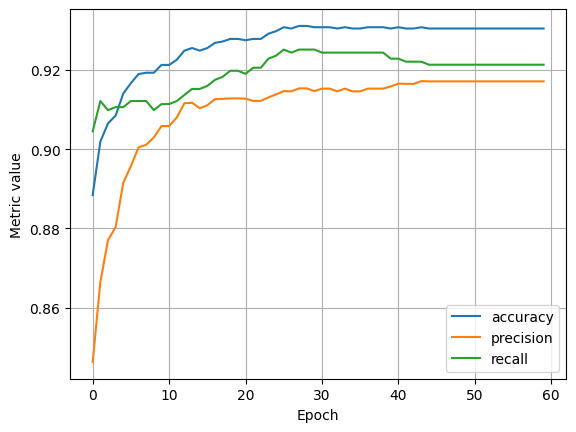

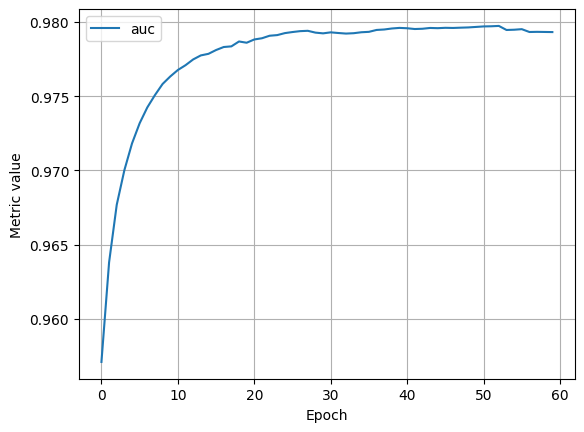

In [22]:
settings_all_features = ml_edu.experiment.ExperimentSettings(
    learning_rate=0.001,
    number_epochs=60,
    batch_size=100,
    classification_threshold=0.5,
    input_features=all_input_features,
)

# Modify the following definition of METRICS to generate
# not only accuracy and precision, but also recall:
metrics = [
    keras.metrics.BinaryAccuracy(
        name='accuracy',
        threshold=settings_all_features.classification_threshold,
    ),
    keras.metrics.Precision(
        name='precision',
        thresholds=settings_all_features.classification_threshold,
    ),
    keras.metrics.Recall(
        name='recall', thresholds=settings_all_features.classification_threshold
    ),
    keras.metrics.AUC(num_thresholds=100, name='auc'),
]

# Establish the model's topography.
model_all_features = create_model(settings_all_features, metrics)

# Train the model on the training set.
experiment_all_features = train_model(
    'all features',
    model_all_features,
    train_features,
    train_labels,
    settings_all_features,
)

# Plot metrics vs. epochs
ml_edu.results.plot_experiment_metrics(
    experiment_all_features, ['accuracy', 'precision', 'recall']
)
ml_edu.results.plot_experiment_metrics(experiment_all_features, ['auc'])

assert len(experiment_all_features.epochs) == 60 and len(settings_all_features.input_features) == 7
experiment_all_features.metrics_history.to_csv(RESULTS / 'rice_all_features_history.csv', index=False)
experiment_all_features.model.save(MODELS / 'rice_all_features.keras')
mark_task('all_features_training_60_epochs', epochs=60, features=list(settings_all_features.input_features), classification_threshold=float(settings_all_features.classification_threshold))

## Evaluate full-featured model on validation split

In [23]:
validation_metrics_all_features = experiment_all_features.evaluate(
    validation_features,
    validation_labels,
)
compare_train_validation(experiment_all_features, validation_metrics_all_features)

pd.DataFrame([validation_metrics_all_features]).to_csv(RESULTS / 'rice_all_features_validation.csv', index=False)
mark_task('all_features_validation', metrics={k:float(v) for k,v in validation_metrics_all_features.items()})

Comparing metrics between train and validation:
------
Train accuracy: 0.9304
Validation accuracy:  0.9108
------
Train auc: 0.9793
Validation auc:  0.9712
------
Train loss: 0.1790
Validation loss:  0.2155
------
Train precision: 0.9171
Validation precision:  0.8902
------
Train recall: 0.9213
Validation recall:  0.9112


This second model has closer train and validation metrics, suggesting it overfit less to the training data.

# Comparing our two models

With our simple experimentation framework, we can keep track of which experiments we ran, and what the results were. We also defined a helper function which allows us to easily compare two or more models, both during training and when evaluated on the validation set.

,experiment,accuracy,auc,loss,precision,recall
0,baseline,0.9,1.0,0.2,0.8,0.9
1,all features,0.9,1.0,0.2,0.9,0.9


The all-feature experiment changes the threshold from 0.35 to 0.5 as well, so accuracy/precision/recall changes cannot be attributed to feature count alone. AUC does not depend on that one classification threshold.


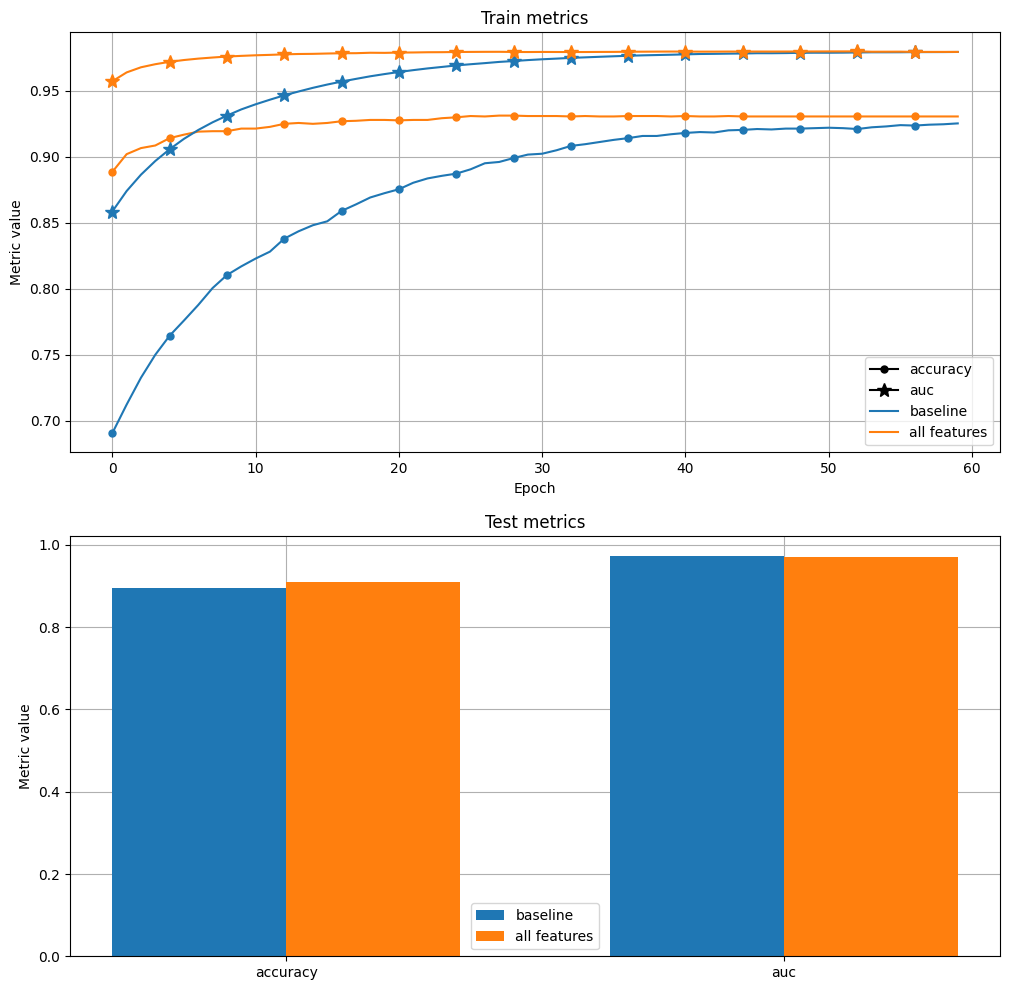

In [24]:
ml_edu.results.compare_experiment([experiment, experiment_all_features],
                                  ['accuracy', 'auc'],
                                  validation_features, validation_labels)

validation_comparison = pd.DataFrame([{'experiment': e.name, **m} for e,m in
    [(experiment,validation_metrics),(experiment_all_features,validation_metrics_all_features)]])
display(validation_comparison)
validation_comparison.to_csv(RESULTS / 'rice_model_comparison.csv', index=False)
print('The all-feature experiment changes the threshold from 0.35 to 0.5 as well, so accuracy/precision/recall changes cannot be attributed to feature count alone. AUC does not depend on that one classification threshold.')
mark_task('model_comparison', metrics=validation_comparison.to_dict(orient='records'))

Comparing the two models, both have AUC of ~.97-.98. There does not seem to be a large gain in model quality when adding the other four features, which makes sense, given that many of the features (area, perimeter, and convex area, for example) are interrelated.

# Computing the final test metrics

To estimate the peformance of our model on unseen data, we can now compute the metrics of the best model on the test data. This final step must be done once experimentation is over and we have selected the model we want to use. Any model comparison must be done using the validation set, to avoid accidentally selecting a model which is tailored for our test set. 

This final step is also the opportunity to check for potential overfitting: if the validation and test metrics are very different, it might be a sign that the selection process done using the validation set led to a model that doesn't generalize well, possibly because the validation set is not representative of the overall data distribution. In that case, the best solution is to shuffle the data and re-assign the train, validation, and test sets, before running your experiments again.

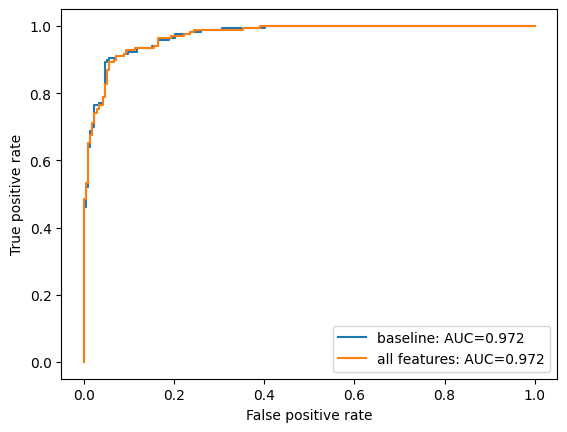

{'selected_model': 'baseline', 'threshold': 0.5499999999999999, 'accuracy': 0.9133858267716536, 'auc': np.float64(0.9755228683061365), 'macro_f1': 0.908735890828585, 'balanced_accuracy': np.float64(0.9047201792691335)}
Confusion matrix [negative, positive]: [[217  12]
 [ 21 131]]


In [25]:
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score)
import matplotlib.pyplot as plt
# Select both the feature set and threshold using validation data only.
candidates = [(experiment, validation_metrics), (experiment_all_features, validation_metrics_all_features)]
selected_experiment = max(candidates, key=lambda item: item[1]['auc'])[0]
def probabilities(exp, frame):
    x = {k: frame[k].to_numpy() for k in exp.settings.input_features}
    return exp.model.predict(x, verbose=0).reshape(-1)
valid_p = probabilities(selected_experiment, validation_features)
threshold_rows=[]
for threshold in np.linspace(.05,.95,19):
    pred = valid_p >= threshold
    threshold_rows.append({'threshold':threshold,'accuracy':accuracy_score(validation_labels,pred),
        'precision':precision_score(validation_labels,pred,zero_division=0),
        'recall':recall_score(validation_labels,pred,zero_division=0),
        'macro_f1':f1_score(validation_labels,pred,average='macro',zero_division=0)})
threshold_table=pd.DataFrame(threshold_rows)
selected_threshold=float(threshold_table.loc[threshold_table.macro_f1.idxmax(),'threshold'])
threshold_table.to_csv(RESULTS/'rice_validation_thresholds.csv',index=False)
for exp,_ in candidates:
    p=probabilities(exp,validation_features); fpr,tpr,_=roc_curve(validation_labels,p)
    plt.plot(fpr,tpr,label=f'{exp.name}: AUC={roc_auc_score(validation_labels,p):.3f}')
plt.xlabel('False positive rate');plt.ylabel('True positive rate');plt.legend();plt.show()
test_p=probabilities(selected_experiment,test_features);test_pred=test_p>=selected_threshold
test_metrics={'selected_model':selected_experiment.name,'threshold':selected_threshold,
 'accuracy':accuracy_score(test_labels,test_pred),'auc':roc_auc_score(test_labels,test_p),
 'macro_f1':f1_score(test_labels,test_pred,average='macro'),
 'balanced_accuracy':balanced_accuracy_score(test_labels,test_pred)}
print(test_metrics);print('Confusion matrix [negative, positive]:',confusion_matrix(test_labels,test_pred))
assert set(train_data.index)==set(training_rows.index)
assert set(train_data.index).isdisjoint(test_data.index)
pd.DataFrame([test_metrics]).to_csv(RESULTS/'rice_test_metrics.csv',index=False)

assert test_p.shape == test_labels.shape == (381,)
pd.DataFrame({'row':test_data.index, 'observed':test_labels, 'probability':test_p,
              'predicted':test_pred.astype(int)}).to_csv(RESULTS / 'rice_test_predictions.csv', index=False)
mark_task('heldout_test', **{k:(float(v) if isinstance(v,(float,np.floating)) else v) for k,v in test_metrics.items()}, test_rows=len(test_labels))

The test metrics above are measured outputs. Similar validation and test performance supports this dataset split; it does not guarantee performance under a new population or sensor domain.


## Save computational progress
Run the final cell after every exercise cell. It checks the required computational stages ran in this session, saves timestamped evidence, and synchronizes results/models to Drive. Save the notebook itself to retain its cell outputs. Website quiz/exercise progress is tracked separately by Google.


In [26]:
finish_run(COLAB_CONTEXT)

Saved computational progress and artifacts to: /content/drive/MyDrive/HaiLong_Colab_Results/01_google_mlcc
Full original computational stages executed: 02_binary_classification_rice.ipynb
Completion evidence: results/02_binary_classification_rice_completion.json


{'notebook': '02_binary_classification_rice.ipynb',
 'run_id': 'd01c2081-cb15-459e-80b3-7a34ebea6597',
 'started_at_utc': '2026-10-03T06:04:11.032924+00:00',
 'in_hosted_colab': True,
 'quick_run': False,
 'python': '3.12.13',
 'versions': {'google-ml-edu': '0.1.3',
  'tensorflow': '2.21.0',
  'keras': '3.13.2',
  'numpy': '2.0.2',
  'pandas': '2.2.2',
  'matplotlib': '3.10.0',
  'plotly': '5.24.1',
  'scikit-learn': '1.6.1'},
 'original_source': 'https://raw.githubusercontent.com/google/eng-edu/main/ml/cc/exercises/binary_classification_rice.ipynb',
 'data_sources': [{'filename': 'Rice_Cammeo_Osmancik.csv',
   'url': 'https://download.mlcc.google.com/mledu-datasets/Rice_Cammeo_Osmancik.csv',
   'sha256': '15234fbc17f2b57a05e81d1088a18c0f0aded87c4397c72437eda03f54acdc2c',
   'rows': 3810}],
 'visualization_adaptation': None,
 'finished_at_utc': '2026-10-03T06:04:54.290705+00:00',
 'full_original_computational_tasks_executed': True,
 'course_website_completion_confirmed': False,
 'requi

In [27]:
# Added by the course runner: inspect the executed runtime, not coursework.
import os as _hailong_os, json as _hailong_json, platform as _hailong_platform
_hailong_evidence = {
    'python': _hailong_platform.python_version(),
    'quick_run': bool(globals().get('QUICK_RUN', False)),
    'course_smoke': _hailong_os.environ.get('COURSE_SMOKE', '0'),
    'keras_backend': _hailong_os.environ.get('KERAS_BACKEND'),
    'legacy_keras': _hailong_os.environ.get('TF_USE_LEGACY_KERAS'),
}
print('__HAILONG_RUNTIME_EVIDENCE__' + _hailong_json.dumps(_hailong_evidence))


__HAILONG_RUNTIME_EVIDENCE__{"python": "3.12.13", "quick_run": false, "course_smoke": "0", "keras_backend": "tensorflow", "legacy_keras": null}
